### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")#llama3-8b-8192

In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.11', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000235D8E6BB60>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000235D93E06E0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
llm = init_chat_model("groq:openai/gpt-oss-20b")#llama3-8b-8192
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.11', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000235D8F33610>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000235D93F0050>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [9]:
graph_builder = StateGraph(State)

# ## Adding node
# graph_builder.add_node(
#     name="chatbot",
#     function=chatbot,
#     inputs={"messages":START},
#     outputs={"messages":END}
# )
## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph = graph_builder.compile()

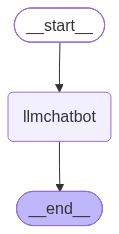

In [10]:
## Visualize the graph
from IPython.display import display,Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
response = graph.invoke({"messages": "Hi"})

In [12]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [13]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I’m doing great—thanks for asking. How about you? Anything interesting on your mind today?


### Chatbot With Tool

In [14]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [16]:
## Custom function
def multifly(a:int,b:int)->int:
    """Multply a and b
    
    Args:
        a (int): first int
        b (int): second int
    
    Returns:
        int: output int
    """
    return a*b

In [17]:
tools=[tool,multifly]

In [18]:
llm_with_tool=llm.bind_tools(tools)

In [19]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.11', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000235D8F33610>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000235D93F0050>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and

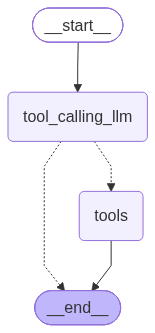

In [20]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [22]:
response['messages'][-1].content

'{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hellogrowth.ai/en/blog/google-ai-news-october-2026", "title": "Google AI news October 2026 · Hello Growth", "content": "Google had a busy first half of October. Most of the news was about agents: AI that does not just answer, but carries out tasks itself. Below, for each development: what happened, who it matters to and where to read more. Checked on 11 October 2026.\\n\\n## 1. The Gemini agent: one agent for all your work\\n\\nOn 8 October Google Cloud announced the Gemini agent: \\"a single, universal agent for work\\". You give it an objective, and it works in Gmail, Docs, Sheets, Chat and Calendar, but also in Slack and Microsoft 365. A coworker agent gets its own Workspace account with an email address, calendar and Drive, acts under its own name and leaves everything in a log. Under the hood, Gemini picks a model for each job, from Google\'s own models

In [23]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_1c7048f8-a8de-4232-bbb0-00635c47671f)
 Call ID: fc_1c7048f8-a8de-4232-bbb0-00635c47671f
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hellogrowth.ai/en/blog/google-ai-news-october-2026", "title": "Google AI news October 2026 · Hello Growth", "content": "Google had a busy first half of October. Most of the news was about agents: AI that does not just answer, but carries out tasks itself. Below, for each development: what happened, who it matters to and where to read more. Checked on 11 October 2026.\n\n## 1. The Ge

In [24]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [25]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_40b1f8b1-462f-44f9-8a7e-bcfe712b2d9a)
 Call ID: fc_40b1f8b1-462f-44f9-8a7e-bcfe712b2d9a
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 1, 2026\n\n10Fold launched MetricsMatter 5.0, an expanded communications intelligence platform that turns media, social, digital, and AI visibility data into B2B business intelligence. It measures medi

### ReAct Agent Architecture

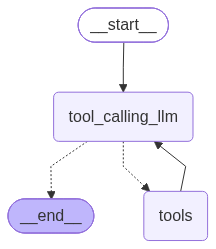

In [26]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [27]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_9aa9c211-b99f-4782-81c5-fd2546ec4292)
 Call ID: fc_9aa9c211-b99f-4782-81c5-fd2546ec4292
  Args:
    query: latest AI news
    search_depth: basic
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=KGcuuhqmPhI", "title": "AI News: 6 New Models & A Nano Banana Killer", "content": "# AI News: 6 New Models & A Nano Banana Killer\n## Channel: Matt Wolfe (verified)\n1.02M subscribers\n184 likes\n\n### Description\n2,631 views\nPosted: 2026-10-16\nGet free credits when you sign up for @GensparkProduct Design here: \n\nThis week in AI: Krea 3

## Adding Memory In Agentic Graph

In [29]:
response=graph.invoke({"messages":"Hello my name is Tharsi"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Tharsi
================================== Ai Message ==================================

Hello Tharsi! 👋 How can I help you today?


In [30]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I’m not sure what your name is. Could you let me know?


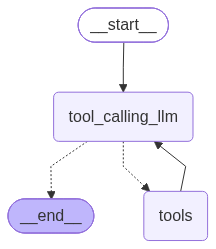

In [31]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
config = {"configurable": {"thread_id": "1"}}
response = graph.invoke({"messages":"Hi my name is Tharsi"}, config=config)
response

{'messages': [HumanMessage(content='Hi my name is Tharsi', additional_kwargs={}, response_metadata={}, id='3c218e85-de86-4a64-ab07-734ba4ac8af9'),
  AIMessage(content='Hello Tharsi! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi my name is Tharsi". Probably wants to respond. No specific question. Just greet.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 350, 'total_tokens': 393, 'completion_time': 0.046721219, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.023503059, 'prompt_tokens_details': None, 'queue_time': 0.347993778, 'total_time': 0.070224278}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_3023a70d60', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a14ed9-084b-74c2-b82f-4dd3facc1bda-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 350, 'output_tokens': 43, 'total_tokens': 393, 'ou

In [33]:
response['messages'][-1].content

'Hello Tharsi! How can I help you today?'

In [34]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Tharsi.


In [35]:
response=graph.invoke({"messages":"Hey do you remember my name"},config=config)

print(response['messages'][-1].content)

Yes, I remember—your name is Tharsi.


### Streaming

In [36]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [37]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

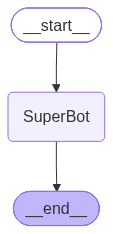

In [38]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [39]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Tharsi And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Tharsi And I like cricket', additional_kwargs={}, response_metadata={}, id='5b581fea-da3c-49d1-b2ce-1cec325d883b'),
  AIMessage(content='Hey Tharsi! 👋🏼 It’s great to meet you. Cricket’s a fascinating sport—do you follow any particular team or player? Or maybe you’ve got a favorite match or moment you’d love to chat about?', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Tharsi And I like cricket". They introduced themselves. They likely want a friendly response. We should respond accordingly. Probably ask about cricket preferences. Also maybe ask if they want to discuss cricket. We must keep it friendly.'}, response_metadata={'token_usage': {'completion_tokens': 111, 'prompt_tokens': 82, 'total_tokens': 193, 'completion_time': 0.113393038, 'completion_tokens_details': {'reasoning_tokens': 56}, 'prompt_time': 0.004012068, 'prompt_tokens_details': None, 'queue_time': 0.34730081, 'total_time': 0.117405106}, 'model_

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [42]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Tharsi And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Tharsi! 👋 Glad to hear you’re into cricket. \n\n- Do you have a favorite team or player you follow?  \n- Are you more into batting, bowling, or fielding?  \n- Want a quick recap of the latest big match or some stats?  \n\nLet me know what you’re curious about, and I’ll dive right in!', additional_kwargs={'reasoning_content': 'User repeats earlier greeting. They want us to respond. We should respond politely. Probably ask about their cricket interests.'}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 278, 'total_tokens': 384, 'completion_time': 0.118241322, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.206968483, 'prompt_tokens_details': None, 'queue_time': 0.438972093, 'total_time': 0.325209805}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_feb9b278f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--

In [43]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Tharsi And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Tharsi And I like cricket', additional_kwargs={}, response_metadata={}, id='1f5ffaa2-df7a-4036-a35f-771d3cf54569'), AIMessage(content='Hello Tharsi! 👋 It’s great to meet someone who loves cricket.  \nWhat’s your favorite part of the game? Do you enjoy batting, bowling, fielding, or maybe following a particular team or player? If you’d like, I can share some interesting facts, recent match highlights, or even help you keep track of upcoming fixtures. Just let me know what you’re interested in!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Tharsi And I like cricket". We need to respond appropriately. The user might want to talk about cricket. We should greet them. Probably ask about cricket. We can ask about what aspects they like: batting, bowling, teams, etc. We can mention we can talk about cricket. So a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 164, 'prompt_tokens': 82, '

In [44]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}


for chunk in graph_builder.stream({'messages':"Hi,My name is Tharsi And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Tharsi! 👋🏼 It’s great to meet a fellow cricket fan. What’s your favorite team or player? Are you into Test matches, ODIs, T20s, or maybe the domestic leagues? Let me know—I’m happy to chat about scores, history, or anything cricket‑related that interests you!', additional_kwargs={'reasoning_content': 'We need to respond friendly, maybe ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 91, 'prompt_tokens': 82, 'total_tokens': 173, 'completion_time': 0.098817491, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.005771554, 'prompt_tokens_details': None, 'queue_time': 0.338268353, 'total_time': 0.104589045}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_f8aab374e8', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a14ee4-3a57-7be1-9b36-f8959931782c-0', tool_calls=[], invalid_tool_calls=[], usage

In [45]:
config = {"configurable": {"thread_id": "5"}}


async for event in graph_builder.astream_events({"messages":["Hi My name is Tharsi and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Tharsi and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a14ee5-1d75-7fa0-a5b3-01de92c49a47', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Tharsi and I like to play cricket', additional_kwargs={}, response_metadata={}, id='0ed0173d-b916-42fe-894f-33197e0506e6')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a14ee5-1d91-7e60-8e3c-50feef0e1893', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:b6a6bf90-672c-e1bc-c906-5a30e7d8e95d'}, 'parent_ids': ['01a14ee5-1d75-7fa0-a5b3-01de92c49a47']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages